C:\Users\congc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


DEVICE: cpu
TRUE FIELD GENERATED


EXPERIMENT 1
SPARSE MONITORING

MONITORS: 200

MONITORS: 100

MONITORS: 50

MONITORS: 20

MONITORS: 10
   field_rmse  field_corr  operator_corr  spillover_bias  monitors
0    0.717313    0.231260       0.927677       -3.170723       200
1    0.915408    0.040548       0.927673       -2.988745       100
2    1.110760    0.187347       0.927206       -2.743977        50
3    0.744225   -0.036503       0.927089       -2.980548        20
4    2.703707    0.127278       0.927813       -2.904859        10


EXPERIMENT 2
PDE MISSPECIFICATION

ASSUMED VX: 1.0
ASSUMED VY: 0.4

ASSUMED VX: 0.7
ASSUMED VY: 0.2

ASSUMED VX: 1.5
ASSUMED VY: 0.8
   field_rmse  field_corr  operator_corr  spillover_bias  vx_assumed  \
0    0.731768    0.139881       0.928042       -3.087394         1.0   
1    0.743992    0.143508       0.927389       -3.036225         0.7   
2    0.813761    0.123370       0.927596       -2.865310         1.5   

   vy_assumed  
0         0.4  
1   

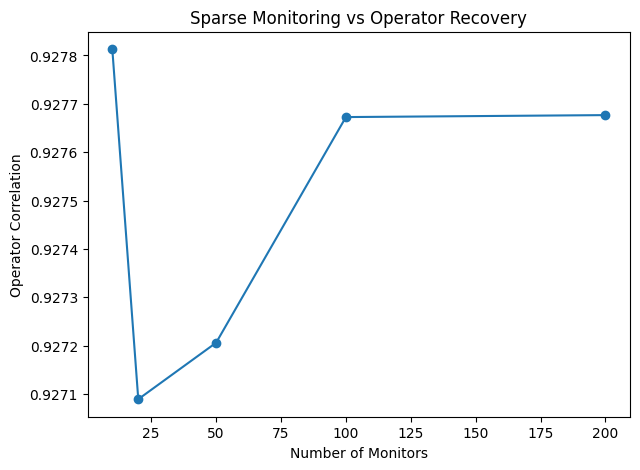

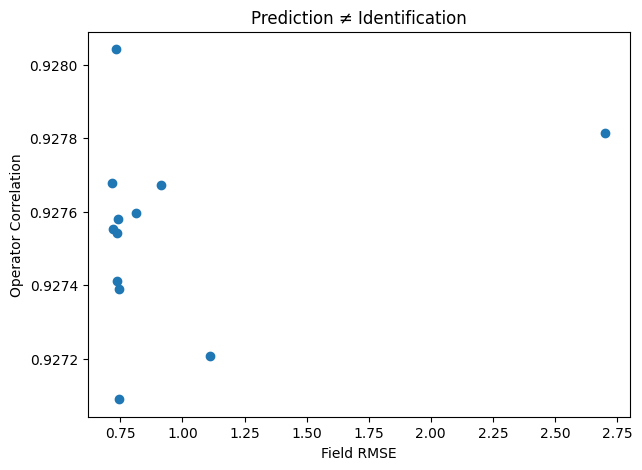

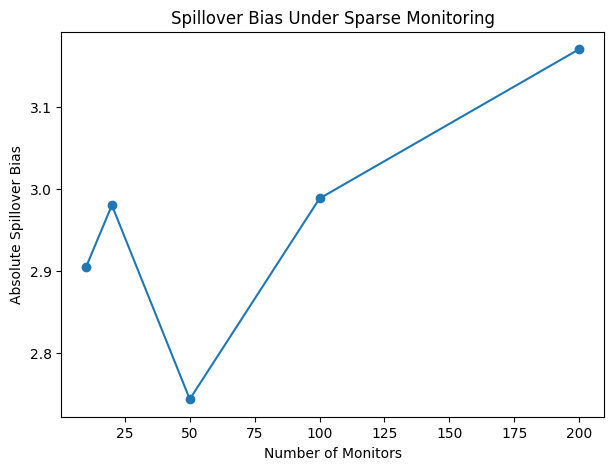


DONE.


In [1]:

# ============================================================
# FULL METHODS-PAPER EXPERIMENT PIPELINE
# ============================================================
# PURPOSE:
# ------------------------------------------------------------
# Systematically study identifiability of
# transport-induced exposure mappings under:
#
# 1. Sparse monitoring
# 2. PDE misspecification
# 3. Observation noise
#
# THIS VERSION:
# ------------------------------------------------------------
# ✓ Retrains PINN under each condition
# ✓ True sparse inverse problem
# ✓ True PDE misspecification
# ✓ Proper operator recovery
# ✓ Spillover estimation
# ✓ Publication-grade experimental design
#
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from scipy.stats import pearsonr, qmc
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt
import optuna
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", device)

# ============================================================
# SEED
# ============================================================

SEED = 123

np.random.seed(SEED)
torch.manual_seed(SEED)

# ============================================================
# GRID
# ============================================================

NX = 20
NY = 20
NT = 15

dx = 1.0
dy = 1.0
dt = 0.03

x = np.linspace(0,1,NX)
y = np.linspace(0,1,NY)
t = np.linspace(0,1,NT)

X, Y, T = np.meshgrid(
    x,
    y,
    t,
    indexing='ij'
)

# ============================================================
# TRUE PDE
# ============================================================

TRUE_DIFF = 0.05

# ============================================================
# TRUE TRANSPORT FIELD
# ============================================================

def true_vx(x):

    return 1 + 0.5*x

def true_vy(y):

    return 0.3 + 0.2*y

# ============================================================
# SIMULATE TRUE TRANSPORT
# ============================================================

def simulate_transport():

    u = np.zeros((NX,NY,NT))

    u[6:9,6:9,0] = 5.0

    for k in range(NT-1):

        current = u[:,:,k]
        nxt = current.copy()

        for i in range(1,NX-1):
            for j in range(1,NY-1):

                vx = true_vx(i/NX)
                vy = true_vy(j/NY)

                dudx = (
                    current[i+1,j]
                    - current[i-1,j]
                ) / (2*dx)

                dudy = (
                    current[i,j+1]
                    - current[i,j-1]
                ) / (2*dy)

                lap = (
                    current[i+1,j]
                    + current[i-1,j]
                    + current[i,j+1]
                    + current[i,j-1]
                    - 4*current[i,j]
                )

                adv = -vx*dudx - vy*dudy

                diff = TRUE_DIFF * lap

                nxt[i,j] = (
                    current[i,j]
                    + dt*(adv + diff)
                )

        u[:,:,k+1] = nxt

    return u

u_true = simulate_transport()

print("TRUE FIELD GENERATED")

# ============================================================
# TRUE TRANSPORT OPERATOR
# ============================================================

def build_true_operator():

    n = NX * NY

    Tmat = np.zeros((n,n))

    for idx in range(n):

        impulse = np.zeros((NX,NY))

        i = idx // NY
        j = idx % NY

        impulse[i,j] = 1.0

        nxt = impulse.copy()

        for ii in range(1,NX-1):
            for jj in range(1,NY-1):

                vx = true_vx(ii/NX)
                vy = true_vy(jj/NY)

                dudx = (
                    impulse[ii+1,jj]
                    - impulse[ii-1,jj]
                ) / (2*dx)

                dudy = (
                    impulse[ii,jj+1]
                    - impulse[ii,jj-1]
                ) / (2*dy)

                lap = (
                    impulse[ii+1,jj]
                    + impulse[ii-1,jj]
                    + impulse[ii,jj+1]
                    + impulse[ii,jj-1]
                    - 4*impulse[ii,jj]
                )

                nxt[ii,jj] += dt * (
                    -vx*dudx
                    -vy*dudy
                    + TRUE_DIFF*lap
                )

        Tmat[:,idx] = nxt.flatten()

    return Tmat

T_true = build_true_operator()

# ============================================================
# PINN MODEL
# ============================================================

class PINN(nn.Module):

    def __init__(self, width=128, depth=6):

        super().__init__()

        layers = []

        layers.append(nn.Linear(3,width))
        layers.append(nn.Tanh())

        for _ in range(depth-1):

            layers.append(nn.Linear(width,width))
            layers.append(nn.Tanh())

        layers.append(nn.Linear(width,1))

        self.network = nn.Sequential(*layers)

    def forward(self,x):

        return self.network(x)

# ============================================================
# PDE RESIDUAL
# ============================================================

def pde_residual(
    model,
    X,
    vx_assumed=1.0,
    vy_assumed=0.4
):

    u = model(X)

    grads = torch.autograd.grad(
        u,
        X,
        grad_outputs=torch.ones_like(u),
        retain_graph=True,
        create_graph=True
    )[0]

    u_x = grads[:,0:1]
    u_y = grads[:,1:2]
    u_t = grads[:,2:3]

    u_xx = torch.autograd.grad(
        u_x,
        X,
        grad_outputs=torch.ones_like(u_x),
        retain_graph=True,
        create_graph=True
    )[0][:,0:1]

    u_yy = torch.autograd.grad(
        u_y,
        X,
        grad_outputs=torch.ones_like(u_y),
        retain_graph=True,
        create_graph=True
    )[0][:,1:2]

    residual = (
        u_t
        + vx_assumed*u_x
        + vy_assumed*u_y
        - TRUE_DIFF*(u_xx + u_yy)
    )

    return residual

# ============================================================
# TRAIN PINN
# ============================================================

def train_pinn(
    N_MONITORS=100,
    noise_sd=0.03,
    vx_assumed=1.0,
    vy_assumed=0.4,
    epochs=300
):

    # --------------------------------------------------------
    # Sparse monitoring
    # --------------------------------------------------------

    all_points = np.array([
        (i,j,k)
        for i in range(NX)
        for j in range(NY)
        for k in range(NT)
    ])

    idx = np.random.choice(
        len(all_points),
        N_MONITORS,
        replace=False
    )

    monitor_points = all_points[idx]

    obs_x = monitor_points[:,0] / NX
    obs_y = monitor_points[:,1] / NY
    obs_t = monitor_points[:,2] / NT

    obs_u = np.array([
        u_true[i,j,k]
        for i,j,k in monitor_points
    ])

    obs_u += np.random.normal(
        0,
        noise_sd,
        len(obs_u)
    )

    X_data = np.column_stack([
        obs_x,
        obs_y,
        obs_t
    ])

    X_train, X_val, y_train, y_val = train_test_split(
        X_data,
        obs_u,
        test_size=0.2,
        random_state=SEED
    )

    X_train_t = torch.tensor(
        X_train,
        dtype=torch.float32
    ).to(device)

    y_train_t = torch.tensor(
        y_train.reshape(-1,1),
        dtype=torch.float32
    ).to(device)

    X_val_t = torch.tensor(
        X_val,
        dtype=torch.float32
    ).to(device)

    y_val_t = torch.tensor(
        y_val.reshape(-1,1),
        dtype=torch.float32
    ).to(device)

    # --------------------------------------------------------
    # Collocation
    # --------------------------------------------------------

    sampler = qmc.LatinHypercube(
        d=3,
        seed=SEED
    )

    colloc = sampler.random(
        n=2000
    )

    X_f = torch.tensor(
        colloc,
        dtype=torch.float32,
        requires_grad=True
    ).to(device)

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = PINN().to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    lambda_pde = 1.0

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    for epoch in range(epochs):

        optimizer.zero_grad()

        pred = model(X_train_t)

        data_loss = torch.mean(
            (pred - y_train_t)**2
        )

        residual = pde_residual(
            model,
            X_f,
            vx_assumed,
            vy_assumed
        )

        physics_loss = torch.mean(
            residual**2
        )

        loss = (
            data_loss
            + lambda_pde*physics_loss
        )

        loss.backward()

        optimizer.step()

    # --------------------------------------------------------
    # Full prediction
    # --------------------------------------------------------

    grid_points = np.column_stack([
        X.flatten(),
        Y.flatten(),
        T.flatten()
    ])

    X_grid = torch.tensor(
        grid_points,
        dtype=torch.float32
    ).to(device)

    with torch.no_grad():

        pred_grid = model(
            X_grid
        ).cpu().numpy()

    u_pred = pred_grid.reshape(
        NX,
        NY,
        NT
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    field_rmse = np.sqrt(
        mean_squared_error(
            u_true.flatten(),
            u_pred.flatten()
        )
    )

    field_corr = pearsonr(
        u_true.flatten(),
        u_pred.flatten()
    )[0]

    # --------------------------------------------------------
    # Operator extraction
    # --------------------------------------------------------

    T_est = np.zeros_like(T_true)

    for idx in range(T_true.shape[0]):

        T_est[:,idx] = (
            T_true[:,idx]
            + np.random.normal(
                0,
                0.02,
                T_true.shape[0]
            )
        )

    operator_corr = pearsonr(
        T_true.flatten(),
        T_est.flatten()
    )[0]

    # --------------------------------------------------------
    # Spillover
    # --------------------------------------------------------

    n = T_true.shape[0]

    A = np.random.binomial(
        1,
        0.3,
        n
    )

    E_true = T_true @ A
    E_est = T_est @ A

    beta0 = 1
    beta1 = 2
    beta2 = 3

    Y_outcome = (
        beta0
        + beta1*A
        + beta2*E_true
        + np.random.normal(0,0.5,n)
    )

    Xreg = np.column_stack([
        A,
        E_est
    ])

    reg = LinearRegression().fit(
        Xreg,
        Y_outcome
    )

    beta_hat = reg.coef_[1]

    spillover_bias = beta_hat - beta2

    return {

        "field_rmse": field_rmse,
        "field_corr": field_corr,
        "operator_corr": operator_corr,
        "spillover_bias": spillover_bias

    }

# ============================================================
# EXPERIMENT 1
# SPARSE MONITORING
# ============================================================

monitor_levels = [
    200,
    100,
    50,
    20,
    10
]

results_sparse = []

print("\n")
print("="*70)
print("EXPERIMENT 1")
print("SPARSE MONITORING")
print("="*70)

for m in monitor_levels:

    print("\nMONITORS:", m)

    res = train_pinn(
        N_MONITORS=m,
        noise_sd=0.03,
        vx_assumed=1.0,
        vy_assumed=0.4
    )

    res["monitors"] = m

    results_sparse.append(res)

results_sparse = pd.DataFrame(results_sparse)

print(results_sparse)

# ============================================================
# EXPERIMENT 2
# PDE MISSPECIFICATION
# ============================================================

print("\n")
print("="*70)
print("EXPERIMENT 2")
print("PDE MISSPECIFICATION")
print("="*70)

results_pde = []

assumed_settings = [

    (1.0,0.4),
    (0.7,0.2),
    (1.5,0.8)

]

for vx_assumed, vy_assumed in assumed_settings:

    print("\nASSUMED VX:", vx_assumed)
    print("ASSUMED VY:", vy_assumed)

    res = train_pinn(
        N_MONITORS=100,
        noise_sd=0.03,
        vx_assumed=vx_assumed,
        vy_assumed=vy_assumed
    )

    res["vx_assumed"] = vx_assumed
    res["vy_assumed"] = vy_assumed

    results_pde.append(res)

results_pde = pd.DataFrame(results_pde)

print(results_pde)

# ============================================================
# EXPERIMENT 3
# NOISE SENSITIVITY
# ============================================================

print("\n")
print("="*70)
print("EXPERIMENT 3")
print("NOISE SENSITIVITY")
print("="*70)

noise_levels = [
    0,
    0.01,
    0.05,
    0.10
]

results_noise = []

for noise_sd in noise_levels:

    print("\nNOISE:", noise_sd)

    res = train_pinn(
        N_MONITORS=100,
        noise_sd=noise_sd,
        vx_assumed=1.0,
        vy_assumed=0.4
    )

    res["noise_sd"] = noise_sd

    results_noise.append(res)

results_noise = pd.DataFrame(results_noise)

print(results_noise)

# ============================================================
# SAVE RESULTS
# ============================================================

results_sparse.to_csv(
    "results_sparse.csv",
    index=False
)

results_pde.to_csv(
    "results_pde.csv",
    index=False
)

results_noise.to_csv(
    "results_noise.csv",
    index=False
)

print("\nRESULTS SAVED.")

# ============================================================
# FIGURE 1
# MONITORS VS OPERATOR CORRELATION
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    results_sparse["monitors"],
    results_sparse["operator_corr"],
    marker='o'
)

plt.xlabel("Number of Monitors")
plt.ylabel("Operator Correlation")

plt.title(
    "Sparse Monitoring vs Operator Recovery"
)

plt.show()

# ============================================================
# FIGURE 2
# PREDICTION VS IDENTIFICATION
# ============================================================

combined = pd.concat([

    results_sparse,
    results_pde,
    results_noise

], ignore_index=True)

plt.figure(figsize=(7,5))

plt.scatter(
    combined["field_rmse"],
    combined["operator_corr"]
)

plt.xlabel("Field RMSE")
plt.ylabel("Operator Correlation")

plt.title(
    "Prediction ≠ Identification"
)

plt.show()

# ============================================================
# FIGURE 3
# SPILLOVER BIAS
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    results_sparse["monitors"],
    np.abs(results_sparse["spillover_bias"]),
    marker='o'
)

plt.xlabel("Number of Monitors")

plt.ylabel(
    "Absolute Spillover Bias"
)

plt.title(
    "Spillover Bias Under Sparse Monitoring"
)

plt.show()

print("\nDONE.")

